In [ ]:
import os

os.listdir()

['.config', 'dataset_set_D_telecomunicaciones.xlsx', 'sample_data']

In [ ]:
import pandas as pd

df = pd.read_excel("dataset_set_D_telecomunicaciones.xlsx")

df.head()

,fecha_registro,region,tipo_servicio,trafico_datos_gb,latencia_ms,incidencias_reportadas,tickets_soporte,tiempo_resolucion_hr,clientes_afectados,cumplimiento_sla
0,2025-03-01,Centro,Empresas,457.8,21.3,0,27,22.4,144,No cumple
1,2025-03-02,Norte,Internet Hogar,383.4,36.5,13,19,39.4,290,No cumple
2,2025-03-03,Norte,Empresas,457.3,97.4,7,15,1.7,427,Cumple
3,2025-03-04,Norte,Móvil,62.5,119.4,12,30,38.2,116,Cumple
4,2025-03-05,Norte,Empresas,356.1,111.0,9,30,21.5,389,No cumple


In [ ]:
print("Dimensiones del dataset:", df.shape)

print("\nColumnas del dataset:")
for columna in df.columns:
    print("-", columna)

Dimensiones del dataset: (200, 10)

Columnas del dataset:
- fecha_registro
- region
- tipo_servicio
- trafico_datos_gb
- latencia_ms
- incidencias_reportadas
- tickets_soporte
- tiempo_resolucion_hr
- clientes_afectados
- cumplimiento_sla


In [ ]:
print("Información general del dataset:")
df.info()

print("\nValores nulos por columna:")
print(df.isnull().sum())

Información general del dataset:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 10 columns):
 #   Column                  Non-Null Count  Dtype         
---  ------                  --------------  -----         
 0   fecha_registro          200 non-null    datetime64[ns]
 1   region                  200 non-null    object        
 2   tipo_servicio           200 non-null    object        
 3   trafico_datos_gb        200 non-null    float64       
 4   latencia_ms             200 non-null    float64       
 5   incidencias_reportadas  200 non-null    int64         
 6   tickets_soporte         200 non-null    int64         
 7   tiempo_resolucion_hr    200 non-null    float64       
 8   clientes_afectados      200 non-null    int64         
 9   cumplimiento_sla        200 non-null    object        
dtypes: datetime64[ns](1), float64(3), int64(3), object(3)
memory usage: 15.8+ KB

Valores nulos por columna:
fecha_registro            0
regi

In [ ]:
df.describe().round(2)

,fecha_registro,trafico_datos_gb,latencia_ms,incidencias_reportadas,tickets_soporte,tiempo_resolucion_hr,clientes_afectados
count,200,200.00,200.00,200.00,200.00,200.00,200.00
mean,2025-06-08 12:00:00,287.23,64.86,13.54,31.39,25.33,265.38
min,2025-03-01 00:00:00,50.50,11.20,0.00,5.00,1.20,10.00
25%,2025-04-19 18:00:00,181.82,36.88,6.00,18.75,12.70,146.50
50%,2025-06-08 12:00:00,289.10,64.90,14.00,31.00,26.35,281.50
75%,2025-07-28 06:00:00,398.75,91.72,20.00,44.00,37.72,376.00
max,2025-09-16 00:00:00,497.90,119.90,29.00,59.00,47.20,499.00
std,NaN,130.55,32.91,8.42,15.52,13.67,139.99


In [ ]:
print("Registros por región:")
print(df["region"].value_counts())

print("\nRegistros por tipo de servicio:")
print(df["tipo_servicio"].value_counts())

print("\nCumplimiento de SLA:")
print(df["cumplimiento_sla"].value_counts())

Registros por región:
region
Centro    68
Sur       67
Norte     65
Name: count, dtype: int64

Registros por tipo de servicio:
tipo_servicio
Internet Hogar    79
Empresas          64
Móvil             57
Name: count, dtype: int64

Cumplimiento de SLA:
cumplimiento_sla
No cumple    104
Cumple        96
Name: count, dtype: int64


In [ ]:
print("Registros duplicados:", df.duplicated().sum())

print("\nRegiones encontradas:")
print(df["region"].unique())

print("\nTipos de servicio encontrados:")
print(df["tipo_servicio"].unique())

print("\nEstados de cumplimiento SLA:")
print(df["cumplimiento_sla"].unique())

Registros duplicados: 0

Regiones encontradas:
['Centro' 'Norte' 'Sur']

Tipos de servicio encontrados:
['Empresas' 'Internet Hogar' 'Móvil']

Estados de cumplimiento SLA:
['No cumple' 'Cumple']


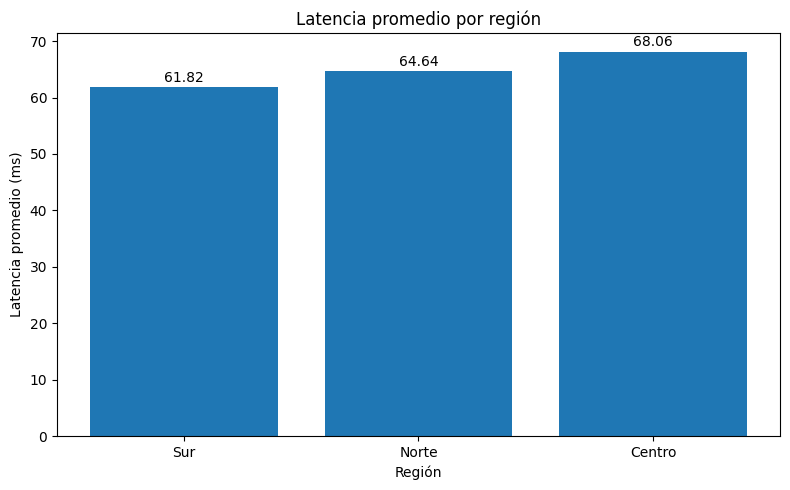

In [ ]:
import matplotlib.pyplot as plt

latencia_region = df.groupby("region")["latencia_ms"].mean().sort_values()

plt.figure(figsize=(8, 5))
barras = plt.bar(latencia_region.index, latencia_region.values)

plt.title("Latencia promedio por región")
plt.xlabel("Región")
plt.ylabel("Latencia promedio (ms)")

for barra in barras:
    plt.text(
        barra.get_x() + barra.get_width()/2,
        barra.get_height() + 1,
        f"{barra.get_height():.2f}",
        ha="center"
    )

plt.tight_layout()
plt.show()

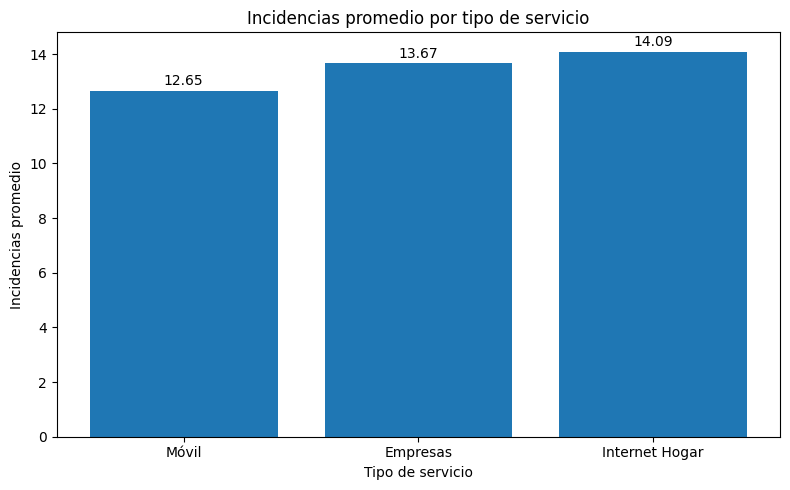

In [ ]:
incidencias_servicio = df.groupby("tipo_servicio")["incidencias_reportadas"].mean().sort_values()

plt.figure(figsize=(8, 5))
barras = plt.bar(incidencias_servicio.index, incidencias_servicio.values)

plt.title("Incidencias promedio por tipo de servicio")
plt.xlabel("Tipo de servicio")
plt.ylabel("Incidencias promedio")

for barra in barras:
    plt.text(
        barra.get_x() + barra.get_width()/2,
        barra.get_height() + 0.2,
        f"{barra.get_height():.2f}",
        ha="center"
    )

plt.tight_layout()
plt.show()

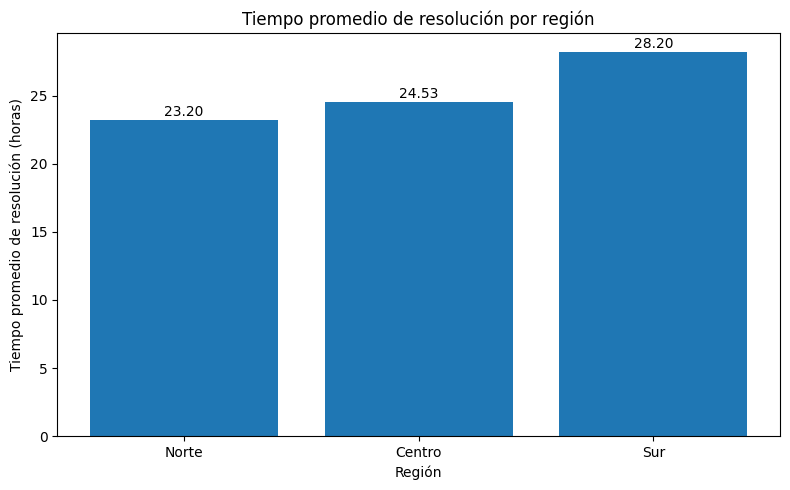

In [ ]:
resolucion_region = df.groupby("region")["tiempo_resolucion_hr"].mean().sort_values()

plt.figure(figsize=(8, 5))
barras = plt.bar(resolucion_region.index, resolucion_region.values)

plt.title("Tiempo promedio de resolución por región")
plt.xlabel("Región")
plt.ylabel("Tiempo promedio de resolución (horas)")

for barra in barras:
    plt.text(
        barra.get_x() + barra.get_width()/2,
        barra.get_height() + 0.3,
        f"{barra.get_height():.2f}",
        ha="center"
    )

plt.tight_layout()
plt.show()

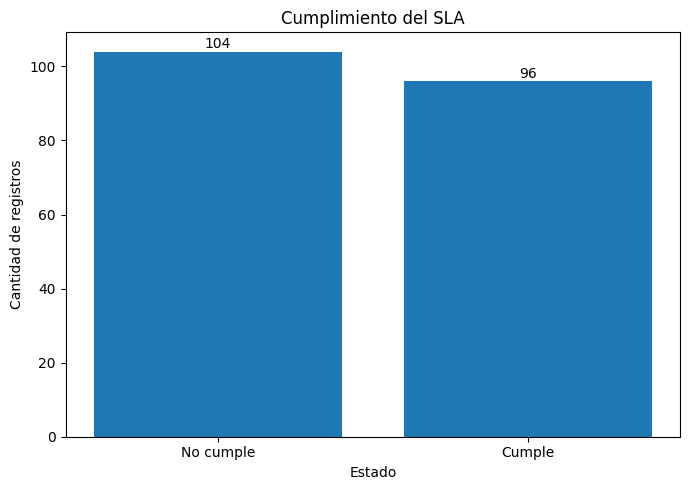

In [ ]:
sla = df["cumplimiento_sla"].value_counts()

plt.figure(figsize=(7, 5))
barras = plt.bar(sla.index, sla.values)

plt.title("Cumplimiento del SLA")
plt.xlabel("Estado")
plt.ylabel("Cantidad de registros")

for barra in barras:
    plt.text(
        barra.get_x() + barra.get_width()/2,
        barra.get_height() + 1,
        f"{int(barra.get_height())}",
        ha="center"
    )

plt.tight_layout()
plt.show()

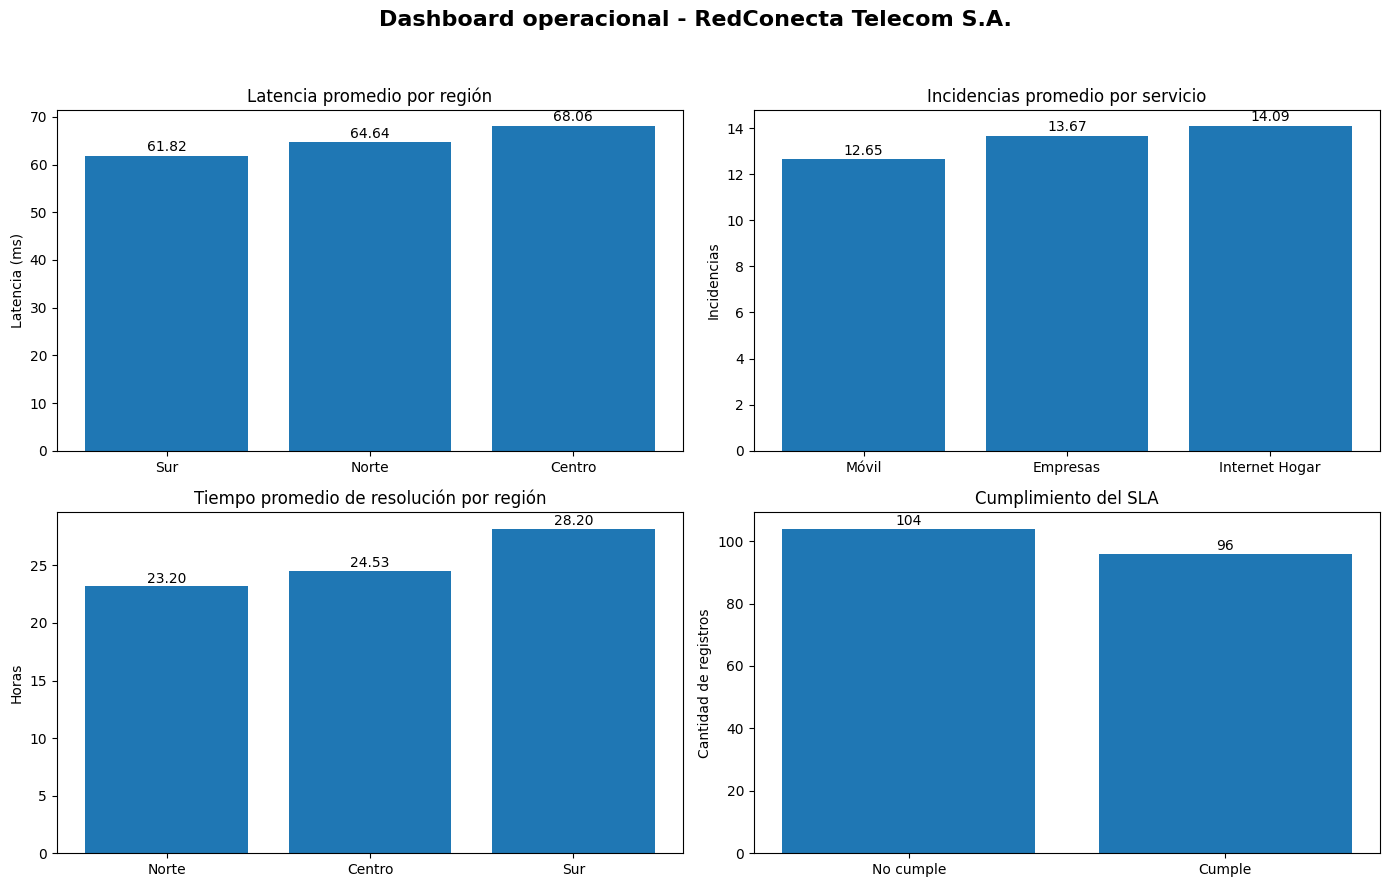

In [ ]:
import matplotlib.pyplot as plt

fig, axs = plt.subplots(2, 2, figsize=(14, 9))
fig.suptitle(
    "Dashboard operacional - RedConecta Telecom S.A.",
    fontsize=16,
    fontweight="bold"
)

# 1. Latencia promedio por región
latencia_region = df.groupby("region")["latencia_ms"].mean().sort_values()
axs[0, 0].bar(latencia_region.index, latencia_region.values)
axs[0, 0].set_title("Latencia promedio por región")
axs[0, 0].set_ylabel("Latencia (ms)")

for i, valor in enumerate(latencia_region.values):
    axs[0, 0].text(i, valor + 1, f"{valor:.2f}", ha="center")

# 2. Incidencias promedio por tipo de servicio
incidencias_servicio = (
    df.groupby("tipo_servicio")["incidencias_reportadas"]
    .mean()
    .sort_values()
)

axs[0, 1].bar(
    incidencias_servicio.index,
    incidencias_servicio.values
)
axs[0, 1].set_title("Incidencias promedio por servicio")
axs[0, 1].set_ylabel("Incidencias")

for i, valor in enumerate(incidencias_servicio.values):
    axs[0, 1].text(i, valor + 0.2, f"{valor:.2f}", ha="center")

# 3. Tiempo promedio de resolución por región
resolucion_region = (
    df.groupby("region")["tiempo_resolucion_hr"]
    .mean()
    .sort_values()
)

axs[1, 0].bar(
    resolucion_region.index,
    resolucion_region.values
)
axs[1, 0].set_title("Tiempo promedio de resolución por región")
axs[1, 0].set_ylabel("Horas")

for i, valor in enumerate(resolucion_region.values):
    axs[1, 0].text(i, valor + 0.3, f"{valor:.2f}", ha="center")

# 4. Cumplimiento del SLA
sla = df["cumplimiento_sla"].value_counts()

axs[1, 1].bar(sla.index, sla.values)
axs[1, 1].set_title("Cumplimiento del SLA")
axs[1, 1].set_ylabel("Cantidad de registros")

for i, valor in enumerate(sla.values):
    axs[1, 1].text(i, valor + 1, str(valor), ha="center")

plt.tight_layout(rect=[0, 0, 1, 0.95])
plt.show()

In [ ]:
variables_numericas = [
    "trafico_datos_gb",
    "latencia_ms",
    "incidencias_reportadas",
    "tickets_soporte",
    "tiempo_resolucion_hr",
    "clientes_afectados"
]

correlaciones = df[variables_numericas].corr()

correlaciones.round(2)

,trafico_datos_gb,latencia_ms,incidencias_reportadas,tickets_soporte,tiempo_resolucion_hr,clientes_afectados
trafico_datos_gb,1.00,-0.08,-0.12,-0.08,-0.21,-0.04
latencia_ms,-0.08,1.00,0.01,-0.20,-0.07,-0.03
incidencias_reportadas,-0.12,0.01,1.00,-0.07,-0.00,0.06
tickets_soporte,-0.08,-0.20,-0.07,1.00,0.07,-0.01
tiempo_resolucion_hr,-0.21,-0.07,-0.00,0.07,1.00,0.12
clientes_afectados,-0.04,-0.03,0.06,-0.01,0.12,1.00


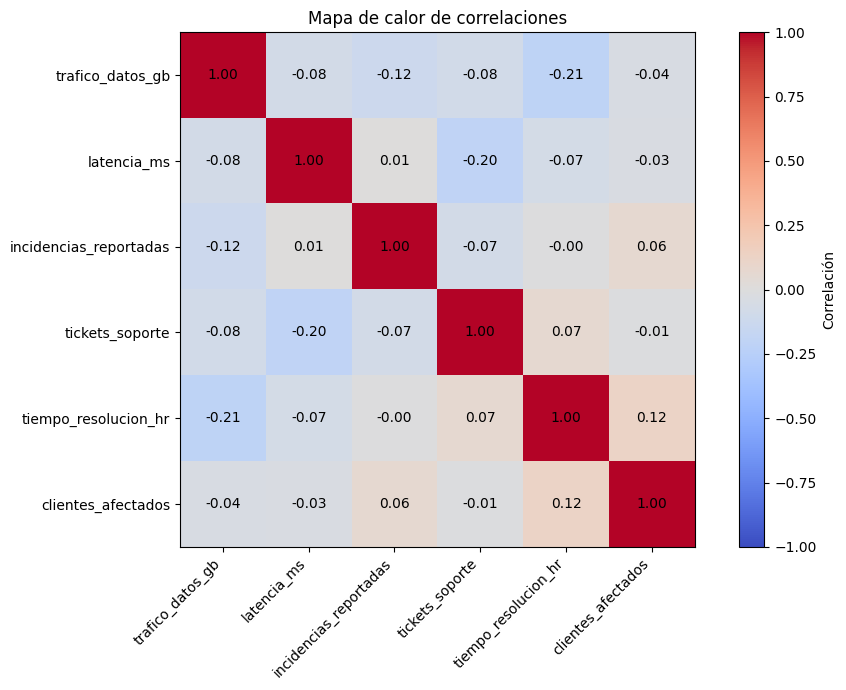

In [ ]:
plt.figure(figsize=(10, 7))

plt.imshow(correlaciones, cmap="coolwarm", vmin=-1, vmax=1)

plt.colorbar(label="Correlación")

plt.xticks(
    range(len(variables_numericas)),
    variables_numericas,
    rotation=45,
    ha="right"
)

plt.yticks(
    range(len(variables_numericas)),
    variables_numericas
)

for i in range(len(variables_numericas)):
    for j in range(len(variables_numericas)):
        plt.text(
            j, i,
            f"{correlaciones.iloc[i, j]:.2f}",
            ha="center",
            va="center"
        )

plt.title("Mapa de calor de correlaciones")
plt.tight_layout()
plt.show()

In [ ]:
!git init

hint: Using 'master' as the name for the initial branch. This default branch name
hint: is subject to change. To configure the initial branch name to use in all
hint: of your new repositories, which will suppress this warning, call:
hint: 
hint: 	git config --global init.defaultBranch <name>
hint: 
hint: Names commonly chosen instead of 'master' are 'main', 'trunk' and
hint: 'development'. The just-created branch can be renamed via this command:
hint: 
hint: 	git branch -m <name>
Initialized empty Git repository in /content/.git/


In [ ]:
!git branch -m main
!git status

On branch main

No commits yet

Untracked files:
  (use "git add <file>..." to include in what will be committed)
	.config/
	dataset_set_D_telecomunicaciones.xlsx
	sample_data/

nothing added to commit but untracked files present (use "git add" to track)


In [ ]:
!git add dataset_set_D_telecomunicaciones.xlsx
!git status

On branch main

No commits yet

Changes to be committed:
  (use "git rm --cached <file>..." to unstage)
	new file:   dataset_set_D_telecomunicaciones.xlsx

Untracked files:
  (use "git add <file>..." to include in what will be committed)
	.config/
	sample_data/



In [ ]:
!git config user.name "Pablo Sanhueza"
!git config user.email "pablo@redconecta.local"

!git commit -m "Inicio proyecto analisis RedConecta"

[main (root-commit) 4c71cb3] Inicio proyecto analisis RedConecta
 1 file changed, 0 insertions(+), 0 deletions(-)
 create mode 100644 dataset_set_D_telecomunicaciones.xlsx


In [ ]:
!git log --oneline
!git status

4c71cb3 (HEAD -> main) Inicio proyecto analisis RedConecta
On branch main
Untracked files:
  (use "git add <file>..." to include in what will be committed)
	.config/
	sample_data/

nothing added to commit but untracked files present (use "git add" to track)


In [ ]:
!find /content/drive/MyDrive -name "analisis_telecomunicaciones.ipynb" 2>/dev/null

In [1]:
print(df.shape)

NameError: name 'df' is not defined

In [2]:
import pandas as pd

df = pd.read_excel("dataset_set_D_telecomunicaciones.xlsx")
df["fecha_registro"] = pd.to_datetime(df["fecha_registro"])

print("Dataset cargado correctamente")
print("Dimensiones:", df.shape)

Dataset cargado correctamente
Dimensiones: (200, 10)


In [3]:
# Archivo de salida para el Area de Soporte Tecnico

soporte_tecnico = df[[
    "fecha_registro",
    "region",
    "tipo_servicio",
    "incidencias_reportadas",
    "tickets_soporte",
    "tiempo_resolucion_hr"
]].copy()

soporte_tecnico.to_csv(
    "reporte_soporte_tecnico.csv",
    index=False,
    encoding="utf-8-sig"
)

print("Archivo generado correctamente: reporte_soporte_tecnico.csv")
print("Dimensiones:", soporte_tecnico.shape)

soporte_tecnico.head()

Archivo generado correctamente: reporte_soporte_tecnico.csv
Dimensiones: (200, 6)


,fecha_registro,region,tipo_servicio,incidencias_reportadas,tickets_soporte,tiempo_resolucion_hr
0,2025-03-01,Centro,Empresas,0,27,22.4
1,2025-03-02,Norte,Internet Hogar,13,19,39.4
2,2025-03-03,Norte,Empresas,7,15,1.7
3,2025-03-04,Norte,Móvil,12,30,38.2
4,2025-03-05,Norte,Empresas,9,30,21.5


In [4]:
# Archivo de salida para el Area de Experiencia de Clientes

experiencia_clientes = df[[
    "fecha_registro",
    "tipo_servicio",
    "clientes_afectados",
    "latencia_ms",
    "cumplimiento_sla"
]].copy()

experiencia_clientes.to_csv(
    "reporte_experiencia_clientes.csv",
    index=False,
    encoding="utf-8-sig"
)

print("Archivo generado correctamente: reporte_experiencia_clientes.csv")
print("Dimensiones:", experiencia_clientes.shape)

experiencia_clientes.head()

Archivo generado correctamente: reporte_experiencia_clientes.csv
Dimensiones: (200, 5)


,fecha_registro,tipo_servicio,clientes_afectados,latencia_ms,cumplimiento_sla
0,2025-03-01,Empresas,144,21.3,No cumple
1,2025-03-02,Internet Hogar,290,36.5,No cumple
2,2025-03-03,Empresas,427,97.4,Cumple
3,2025-03-04,Móvil,116,119.4,Cumple
4,2025-03-05,Empresas,389,111.0,No cumple


In [5]:
!git add reporte_soporte_tecnico.csv reporte_experiencia_clientes.csv
!git commit -m "Agrega reportes para soporte tecnico y experiencia de clientes"
!git status

fatal: not a git repository (or any of the parent directories): .git
fatal: not a git repository (or any of the parent directories): .git
fatal: not a git repository (or any of the parent directories): .git


In [6]:
!git init
!git branch -M main

!git config user.name "Pablo Sanhueza"
!git config user.email "pablo@redconecta.local"

!git add dataset_set_D_telecomunicaciones.xlsx
!git add reporte_soporte_tecnico.csv
!git add reporte_experiencia_clientes.csv

!git commit -m "Proyecto analisis RedConecta con reportes por area"

!git log --oneline
!git status

hint: Using 'master' as the name for the initial branch. This default branch name
hint: is subject to change. To configure the initial branch name to use in all
hint: of your new repositories, which will suppress this warning, call:
hint: 
hint: 	git config --global init.defaultBranch <name>
hint: 
hint: Names commonly chosen instead of 'master' are 'main', 'trunk' and
hint: 'development'. The just-created branch can be renamed via this command:
hint: 
hint: 	git branch -m <name>
Initialized empty Git repository in /content/.git/
[main (root-commit) e397bb9] Proyecto analisis RedConecta con reportes por area
 3 files changed, 402 insertions(+)
 create mode 100644 dataset_set_D_telecomunicaciones.xlsx
 create mode 100644 reporte_experiencia_clientes.csv
 create mode 100644 reporte_soporte_tecnico.csv
e397bb9 (HEAD -> main) Proyecto analisis RedConecta con reportes por area
On branch main
Untracked files:
  (use "git add <file>..." to include in what will be committed)
	.config/
	sample_

In [7]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [8]:
import os
import shutil

ruta_respaldo = "/content/drive/MyDrive/RedConecta_Proyecto"

os.makedirs(ruta_respaldo, exist_ok=True)

archivos = [
    "dataset_set_D_telecomunicaciones.xlsx",
    "reporte_soporte_tecnico.csv",
    "reporte_experiencia_clientes.csv"
]

for archivo in archivos:
    shutil.copy2("/content/" + archivo, ruta_respaldo + "/" + archivo)

print("Respaldo realizado correctamente")
print("Ubicacion:", ruta_respaldo)
print("Archivos respaldados:")
print(os.listdir(ruta_respaldo))

Respaldo realizado correctamente
Ubicacion: /content/drive/MyDrive/RedConecta_Proyecto
Archivos respaldados:
['dataset_set_D_telecomunicaciones.xlsx', 'reporte_soporte_tecnico.csv', 'reporte_experiencia_clientes.csv']


In [9]:
import os

ruta_respaldo = "/content/drive/MyDrive/RedConecta_Proyecto"

print("CONTENIDO DEL RESPALDO DEL PROYECTO REDCONECTA")
print("-" * 50)

for archivo in os.listdir(ruta_respaldo):
    print("✓", archivo)

print("-" * 50)
print("Total de archivos:", len(os.listdir(ruta_respaldo)))

CONTENIDO DEL RESPALDO DEL PROYECTO REDCONECTA
--------------------------------------------------
✓ dataset_set_D_telecomunicaciones.xlsx
✓ reporte_soporte_tecnico.csv
✓ reporte_experiencia_clientes.csv
--------------------------------------------------
Total de archivos: 3


In [11]:
contenido_readme = """# Proyecto de análisis - RedConecta Telecom S.A.

## Objetivo

Analizar la información operacional de RedConecta Telecom S.A. para identificar diferencias en el desempeño del servicio y generar información que apoye la toma de decisiones relacionadas con la calidad del servicio, soporte técnico y experiencia de clientes.

## Etapas del análisis

1. Carga del dataset de telecomunicaciones mediante Python y Pandas.
2. Revisión de dimensiones, variables y tipos de datos.
3. Verificación de valores nulos, registros duplicados y consistencia de variables categóricas.
4. Análisis estadístico descriptivo de las variables numéricas.
5. Análisis de latencia promedio por región.
6. Análisis de incidencias promedio por tipo de servicio.
7. Análisis del tiempo promedio de resolución por región.
8. Revisión del cumplimiento del SLA.
9. Construcción de un dashboard exploratorio.
10. Análisis de correlaciones entre variables operacionales.
11. Generación de archivos para Soporte Técnico y Experiencia de Clientes.
12. Control de versiones mediante Git y respaldo de los archivos del proyecto.

## Principales resultados

- El dataset contiene 200 registros y 10 variables.
- No se detectaron valores nulos ni registros duplicados.
- La región Centro presentó la mayor latencia promedio, con 68.06 ms.
- Internet Hogar presentó el mayor promedio de incidencias, con 14.09.
- La región Sur presentó el mayor tiempo promedio de resolución, con 28.20 horas.
- Se registraron 104 casos que no cumplen el SLA y 96 que sí cumplen.
- No se observaron correlaciones lineales fuertes entre las variables numéricas analizadas.

## Archivos generados

- dataset_set_D_telecomunicaciones.xlsx
- reporte_soporte_tecnico.csv
- reporte_experiencia_clientes.csv

## Herramientas utilizadas

- Python
- Pandas
- Matplotlib
- Google Colab
- Git
- Google Drive

## Reutilización

El proyecto fue organizado para que el análisis pueda volver a ejecutarse cuando se incorporen nuevos datos. Manteniendo la misma estructura de variables, es posible actualizar el dataset y ejecutar nuevamente el flujo para obtener indicadores, visualizaciones y reportes actualizados.
"""

with open("README.md", "w", encoding="utf-8") as archivo:
    archivo.write(contenido_readme)

print("README.md creado correctamente")

README.md creado correctamente


In [14]:
%%writefile funciones_redconecta.py

import pandas as pd
import numpy as np

def cargar_datos(ruta):
    """Carga el dataset desde un archivo Excel."""
    return pd.read_excel(ruta)

def resumen_calidad(df):
    """Entrega información básica sobre la calidad del dataset."""
    return {
        "registros": len(df),
        "columnas": len(df.columns),
        "valores_nulos": int(df.isnull().sum().sum()),
        "duplicados": int(df.duplicated().sum())
    }

def indicadores_red(df):
    """Calcula indicadores principales del monitoreo de la red."""
    return {
        "latencia_promedio_ms": round(np.mean(df["latencia_ms"]), 2),
        "incidencias_promedio": round(np.mean(df["incidencias_reportadas"]), 2),
        "tiempo_resolucion_promedio_hr": round(
            np.mean(df["tiempo_resolucion_hr"]), 2
        ),
        "clientes_afectados_promedio": round(
            np.mean(df["clientes_afectados"]), 2
        )
    }

def latencia_por_region(df):
    """Calcula la latencia promedio para cada región."""
    return (
        df.groupby("region")["latencia_ms"]
        .mean()
        .round(2)
        .sort_values()
    )

Overwriting funciones_redconecta.py


In [15]:
from funciones_redconecta import (
    cargar_datos,
    resumen_calidad,
    indicadores_red,
    latencia_por_region
)

# Cargar nuevamente el dataset utilizando la función externa
df_modular = cargar_datos("dataset_set_D_telecomunicaciones.xlsx")

print("RESUMEN DE CALIDAD")
print(resumen_calidad(df_modular))

print("\nINDICADORES PRINCIPALES")
print(indicadores_red(df_modular))

print("\nLATENCIA PROMEDIO POR REGION")
print(latencia_por_region(df_modular))

RESUMEN DE CALIDAD
{'registros': 200, 'columnas': 10, 'valores_nulos': 0, 'duplicados': 0}

INDICADORES PRINCIPALES
{'latencia_promedio_ms': np.float64(64.86), 'incidencias_promedio': np.float64(13.54), 'tiempo_resolucion_promedio_hr': np.float64(25.33), 'clientes_afectados_promedio': np.float64(265.38)}

LATENCIA PROMEDIO POR REGION
region
Sur       61.82
Norte     64.64
Centro    68.06
Name: latencia_ms, dtype: float64


In [16]:
# Evaluación de calidad del dataset

print("EVALUACION DE CALIDAD DEL DATASET")
print("-" * 45)

print("Registros:", len(df))
print("Columnas:", len(df.columns))
print("Valores nulos:", df.isnull().sum().sum())
print("Registros duplicados:", df.duplicated().sum())

print("\nRANGOS DE VARIABLES OPERACIONALES")
print("Latencia:", df["latencia_ms"].min(), "-", df["latencia_ms"].max(), "ms")
print("Tráfico:", df["trafico_datos_gb"].min(), "-", df["trafico_datos_gb"].max(), "GB")
print("Incidencias:", df["incidencias_reportadas"].min(), "-", df["incidencias_reportadas"].max())
print("Tickets:", df["tickets_soporte"].min(), "-", df["tickets_soporte"].max())
print("Tiempo resolución:", df["tiempo_resolucion_hr"].min(), "-", df["tiempo_resolucion_hr"].max(), "horas")
print("Clientes afectados:", df["clientes_afectados"].min(), "-", df["clientes_afectados"].max())

print("\nDISTRIBUCION POR REGION")
print(df["region"].value_counts())

print("\nDISTRIBUCION POR TIPO DE SERVICIO")
print(df["tipo_servicio"].value_counts())

print("\nDISTRIBUCION SLA")
print(df["cumplimiento_sla"].value_counts())

EVALUACION DE CALIDAD DEL DATASET
---------------------------------------------
Registros: 200
Columnas: 10
Valores nulos: 0
Registros duplicados: 0

RANGOS DE VARIABLES OPERACIONALES
Latencia: 11.2 - 119.9 ms
Tráfico: 50.5 - 497.9 GB
Incidencias: 0 - 29
Tickets: 5 - 59
Tiempo resolución: 1.2 - 47.2 horas
Clientes afectados: 10 - 499

DISTRIBUCION POR REGION
region
Centro    68
Sur       67
Norte     65
Name: count, dtype: int64

DISTRIBUCION POR TIPO DE SERVICIO
tipo_servicio
Internet Hogar    79
Empresas          64
Móvil             57
Name: count, dtype: int64

DISTRIBUCION SLA
cumplimiento_sla
No cumple    104
Cumple        96
Name: count, dtype: int64
